# TP2

## Extraire les mots clés de tous les documemts CAMille de 1920 avec Yake

### Imports

In [1]:
import os
import yake

In [2]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

https://github.com/INESCTEC/yake

In [3]:
# Choisir une année
year = 1920 # année des jeux olympiques à Anvers

In [4]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

101

In [5]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [6]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

101

In [7]:
for f in sorted(txts)[:10]:
    text = open(os.path.join(txt_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) >= 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB427_1920-01-10_01-00004.txt mentions these keywords: bureau du journal, erdu malle, Bonne fabrique demande, bonne réeom, bons gages, places BUT demande, bureau journal, lee bons, référ. exig, rue Jacques Jor, VENTE PUBLIQUE...
KB_JB838_1920-01-13_01-00005.txt mentions these keywords: Wnrt Itft mmm, Itft mmm aoi, Wnrt Itft, louer maison, Itft mmm, louer petite maison, BOULANGER afrnUmk, louer maison bourgeoise, oriSilrii louer maison, jnrntUi chaud, mmm aoi, DÉSIRE LOUER, Farte Maison Fronçait, VENDRE maison, désire louer Centre, LOUER bon, louer mal, LOUER bel, belle maison, FUS MAITRES-CHEMISIERS...
KB_JB838_1920-01-18_01-00014.txt mentions these keywords: PHARMACIE ORIPEKOVC, enfants grandiront, bon hiver, d'hypophosphiteâ solubles, passeront an bon, base d'huile, morue et d'hypophosphiteâ, tri Brusotlsa, Dépôt sptciaiités Ui’, DIARRHEES PAH ATOME, rue Anfolae-l Dansaeri, BLANC FIXE Préféré, rue Vroissuit, L’HOPITAL BRUXELLES Tiliphbnt, rue dit Lombard, fpm d Mit, rue Anfolae-l,

## Enrechir la liste de stopwords

### Import

In [8]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\marei\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [103]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", 
       "celui", "elles", "ceux", "chez", "leurs", "vers", "déjà", "très", "quelques", "hier", "toute", "devant", "Devant", "DEVANT", "plusieurs",
       "trop", "rien", "dès", "tant", "assez", "alors", "car", "générale", "quand", "dernier", "fit", # pronoms etc.
       "etc", "ETC", "Mme", "MME", "référ", "div", "réf", "serv", "adr", "Aujourd", "aujourd", "AUJOURD", "toujours",  # abbréviations communes
       "cap", "trav", "com", "con", "ord", "pet", "dés", "ecr", "écrire", "prix", "aven", "rue", "adresser", "cherche", 
       "soir", "vendre", "prés", "ans", "mod", "Brux", "BRUX", "demande", "vend", "agence", "maison", "francs", "louer", "Mén", "MÉN", "sér",
       "vente", "avenue", "bonne", "neuf", "nouvelle", "beau", "bon", "place", "heures", "grand", "mois", "jour", "jeune", 
       "grande", "bons", "vente", "avant", "belle", "peu", "société", "commerce", "fille", "occasion", "lieu", "suite",
       "courant", "gros", "près", "petit", "neuve", "heure", "bel", "sér", "dame", "boulevard", "chaussée", "divers", "grands",
       "tél", "TÈL", "Tèl", "téléphone", "meubles", "meublés", "prendre", "cuisine", "jard", "vue", "vis", "pers", "PERS", "Pers", 
       "nom", "bonnes", "petite", "chambre", "occas", "coucher", "offre", "jardin", "garni", "gaz", "femme", "vient",
       "seul", "mètres", "chêne", "quart", "piano", "bas", "maison", "hôtel", "ici", "Saint", "hom", "ménage", "chamb", "démandé", "env", "matin", 
       "cent", "dix", "six", "cinq", "écrit", "cont", "désire", "café", "dos", "ordre", "notaire", "notaires", "bureaux", "bureau", "saint", "part", "jours",
       "cours", "mot", "salle", "homme", "achat", "pris", "villa", "vieux", "rentier", "salon", "fort", "Jean",
       "haut", "service", "Service", "SERVICE", "hui", "HUI", "demi", "présenter", "vendra", "franc", "Franc", "voir", "main",
       "gare", "cuis", "mal", "quartier", "nouveau", "dom", "demander", "bail", "offre", "ventes", # abbréviations et mots présent en grand nombre en raison des petites annonces, nom du journal etc.
       "rua", "rie", "ruo", "uno", "aveo", "ecrire", "ire", "bur", "eor", "rte", "ter", "Franco", "franco", # mots non bien captés par l'OCR
       "Bruxelles", "BRUXELLES", "bruxelles", "brux", "BRUX", "Anvers", "ANVERS", "anvers", "Namur", "MIDI", "Midi", "midi", 
       "Nord", "NORD", "nord", "Paris", "paris", "PARIS", "Louvain", "LOUVAIN", "Liège",
       "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche", # jours de la semaine
       "janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "septembre", "octobre", "novembre", "décembre"] # mois de l'année  
sw = set(sw)


In [105]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [106]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'OBJETS PERDUS \' Dcssinar d\'HC-cullon\' \nP\nerdu malle en cuir noir, \ncontenant modèle en \nbail, bonne réeom|"en.-e \n46, r. de l\'Instruction. a\'.Cv> \nOn d<Mnnn.l<» \nservan ie-cu.sinîÈro. Bons \nrliamlronnerlo et gag. 11X». r. du Tr^ne. Vil \niiuV-.-iiliiiM- cat «le* \n••innilé pour uilne \nbruxel l «>!•«•. E-rr. \nuveo ré 1er. MUUO \n[ jeune Aile ter. dem. place \nJnrês nen-onne «ule. — \nS\'adr. aO), bur. du Journ\'. \n\\n dem., 4,me Emmanuel \nENSEIGNEMENT \nOr Van Driessche, Brax. \nri lie da la camp., propre '

In [107]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [108]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1920_clean.txt!'

In [109]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'OBJETS PERDUS DCSSINAR CULLON ERDU MALLE CUIR NOIR CONTENANT MODÈLE RÉEOM INSTRUCTION MNNN SERVAN SINÎÈRO RLIAMLRONNERLO GAG VIL IIUV IILIIIM CAT INNILÉ UILNE BRUXEL UVEO MUUO AILE JNRÊS NEN ONNE ULE JOURN EMMANUEL ENSEIGNEMENT DRIESSCHE BRAX LIE CAMP PROPRE HONNÊTE SACH MÉN DRUX MEDI IIMIIUL UNIRAI COMPT PACHCCO OUVERT NOUVEAUX CORRI INCE MÉTHODE PRO CÉDÉS NOUVEAUX RENCELENC MENTA PROGRNMM ATALT JOURN NRLUMERLO TLO MUR NRUX DEMOISELLE HONN HER CIIAUFT ILONI FEM POSSIBLE MÉN COURSES ETT ANT DAN '

## Nuage de mots

### Afficher les termes les plus fréquents


In [110]:
frequencies = Counter(after.split())
print(frequencies.most_common(100))

[('ÉTAT', 528), ('BELGE', 449), ('GUERRE', 430), ('BELGIQUE', 428), ('COUR', 358), ('PAYS', 343), ('GOUVERNEMENT', 293), ('FRANÇAIS', 287), ('PARTIE', 286), ('FER', 281), ('TRAVAIL', 279), ('FRANCE', 278), ('CONSEIL', 266), ('GÉNÉRAL', 260), ('LOI', 254), ('MINISTRE', 254), ('TEMPS', 252), ('BELGES', 236), ('PREMIER', 230), ('QUO', 230), ('ANGLAIS', 228), ('PRÉSIDENT', 222), ('SITUATION', 221), ('MARCHÉ', 219), ('POINT', 213), ('LIBRE', 212), ('QUESTION', 212), ('ART', 211), ('AUTO', 210), ('CAPITAL', 208), ('LOT', 206), ('PREMIÈRE', 195), ('PORTE', 194), ('ROI', 194), ('LIT', 194), ('OUVRIER', 193), ('JEAN', 188), ('TOUR', 187), ('VIE', 181), ('MME', 181), ('FOIS', 180), ('COMMISSION', 178), ('CONTENANT', 175), ('PAIX', 174), ('DROIT', 174), ('ALLEMAGNE', 170), ('EAU', 169), ('CAUSE', 168), ('ETAT', 167), ('MONDE', 167), ('FIN', 164), ('UNION', 162), ('CONDITIONS', 161), ('TRAVAUX', 161), ('TORPÉDO', 160), ('MOMENT', 158), ('AFFAIRES', 157), ('OUVRIERS', 157), ('MORT', 157), ('LOUVAIN

### Créer, stocker et afficher le nuage de mots

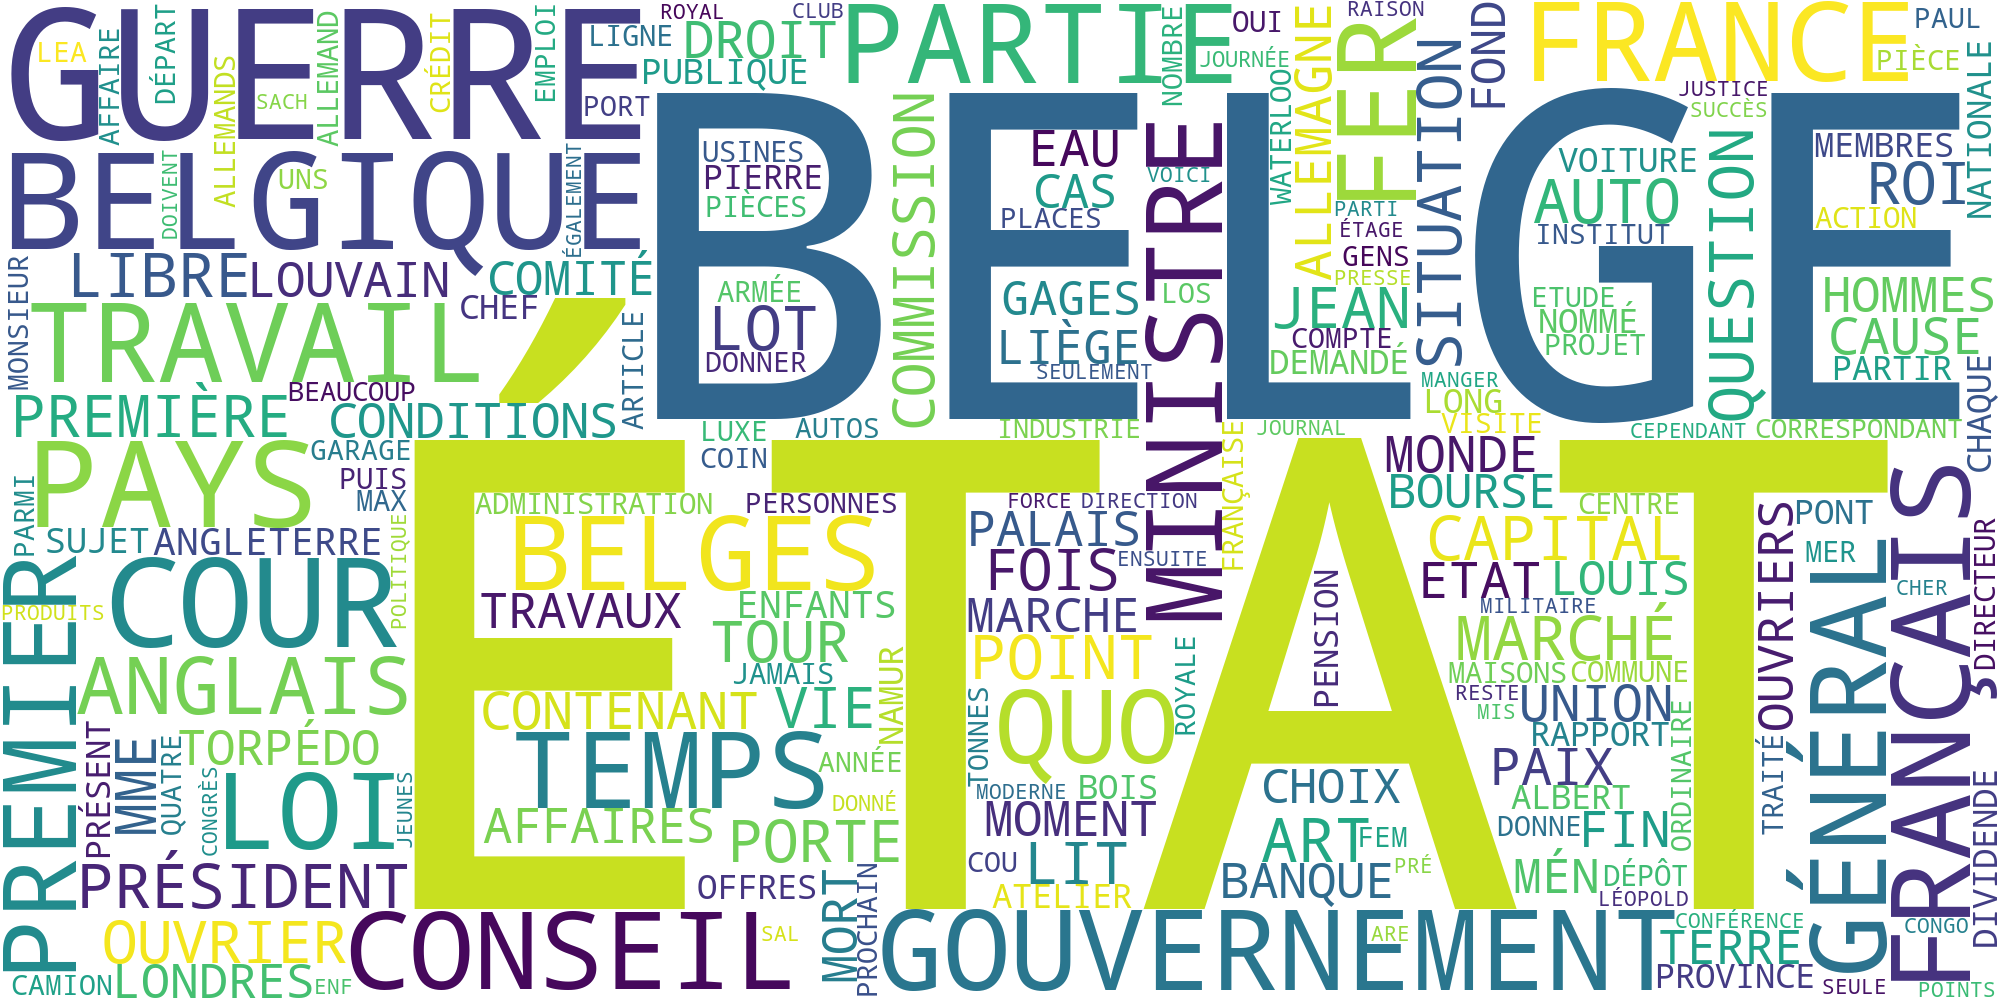

In [111]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## Reconnaissance d'entités nommées avec SpaCy

### Imports

In [ ]:
from collections import defaultdict
import spacy

### Charger SpaCy

In [113]:
nlp = spacy.load('fr_core_news_md')

### Charger les texts de 1920

In [ ]:
# Charger le texte
n=1000000
text = open(os.path.join(temp_path, f'{year}.txt'), encoding='utf-8').read()[:n] # adapté pour prendre le fichier tmp de l'année choisie plus haut



In [126]:
%%time
# Traiter le texte

doc = nlp(text)

CPU times: total: 20.5 s
Wall time: 20.6 s


### Trouver les personnes

In [128]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == ("PER") and len(ent.text) > 3:
        people[ent.text] += 1

In [129]:
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 16 fois dans le corpus
Ledit apparait 16 fois dans le corpus
Fabien apparait 14 fois dans le corpus
Caillaux apparait 13 fois dans le corpus
Kuss apparait 12 fois dans le corpus
Philippe apparait 11 fois dans le corpus
Mireille apparait 10 fois dans le corpus
Louise apparait 9 fois dans le corpus
Jacques apparait 9 fois dans le corpus
Jardin apparait 8 fois dans le corpus
Agence Rossel apparait 8 fois dans le corpus
von Kapp apparait 8 fois dans le corpus
Bonne apparait 6 fois dans le corpus
Rembrandt apparait 6 fois dans le corpus
Ninette apparait 6 fois dans le corpus
Louis XV apparait 6 fois dans le corpus
Bauer apparait 6 fois dans le corpus
Maud apparait 6 fois dans le corpus
M. Masson apparait 5 fois dans le corpus
L. XV apparait 5 fois dans le corpus
Germain apparait 5 fois dans le corpus
Meiser apparait 5 fois dans le corpus
Cinquantenaire apparait 4 fois dans le corpus
Monsieur apparait 4 fois dans le corpus
Arcy apparait 4 fois dans le corpus
Paul-Emile Janson

### Trouver les organisations

In [130]:
# Compter les entités
organisations = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == ("ORG") and len(ent.text) > 3:
        organisations[ent.text] += 1

In [131]:
# Trier et imprimer

sorted_organisations = sorted(organisations.items(), key=lambda kv: kv[1], reverse=True)

for organisation, freq in sorted_organisations[:50]:
    print(f"{organisation} apparait {freq} fois dans le corpus")

Conseil apparait 23 fois dans le corpus
Chambre apparait 18 fois dans le corpus
Société apparait 12 fois dans le corpus
Usines apparait 11 fois dans le corpus
Société des nations apparait 7 fois dans le corpus
Sénat apparait 6 fois dans le corpus
COIFFEUR apparait 5 fois dans le corpus
Conseil d'administration apparait 5 fois dans le corpus
Industrielle apparait 4 fois dans le corpus
Times apparait 4 fois dans le corpus
Conseil d’administration apparait 4 fois dans le corpus
Compagnie apparait 4 fois dans le corpus
Société anonyme apparait 4 fois dans le corpus
Financière de Transports apparait 4 fois dans le corpus
Armée apparait 3 fois dans le corpus
Téléphone apparait 3 fois dans le corpus
Agence Rosscl apparait 3 fois dans le corpus
Agence Rossai apparait 3 fois dans le corpus
les Pharmacies apparait 3 fois dans le corpus
S fr apparait 3 fois dans le corpus
Immédiatement apparait 3 fois dans le corpus
Finances apparait 3 fois dans le corpus
Agence Reuter apparait 3 fois dans le cor

### Trouver les lieux

In [132]:
# Compter les entités
locations = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == ("LOC") and len(ent.text) > 3:
        locations[ent.text] += 1

In [133]:
# Trier et imprimer

sorted_locations = sorted(locations.items(), key=lambda kv: kv[1], reverse=True)

for location, freq in sorted_locations[:50]:
    print(f"{location} apparait {freq} fois dans le corpus")

Bruxelles apparait 210 fois dans le corpus
Belgique apparait 64 fois dans le corpus
Anvers apparait 55 fois dans le corpus
Paris apparait 45 fois dans le corpus
Berlin apparait 40 fois dans le corpus
Brux apparait 37 fois dans le corpus
Londres apparait 33 fois dans le corpus
Nord apparait 28 fois dans le corpus
Angleterre apparait 24 fois dans le corpus
Allemagne apparait 24 fois dans le corpus
Etat apparait 23 fois dans le corpus
Liège apparait 21 fois dans le corpus
Namur apparait 20 fois dans le corpus
Belges apparait 20 fois dans le corpus
Russie apparait 20 fois dans le corpus
Hollande apparait 19 fois dans le corpus
Madrid apparait 19 fois dans le corpus
Laeken apparait 18 fois dans le corpus
France apparait 18 fois dans le corpus
Allemands apparait 18 fois dans le corpus
Bourse apparait 17 fois dans le corpus
BRUXELLES apparait 16 fois dans le corpus
Louvain apparait 16 fois dans le corpus
Ruhr apparait 16 fois dans le corpus
Congo apparait 15 fois dans le corpus
Belge apparait